Text(0, 0.5, 'Density')

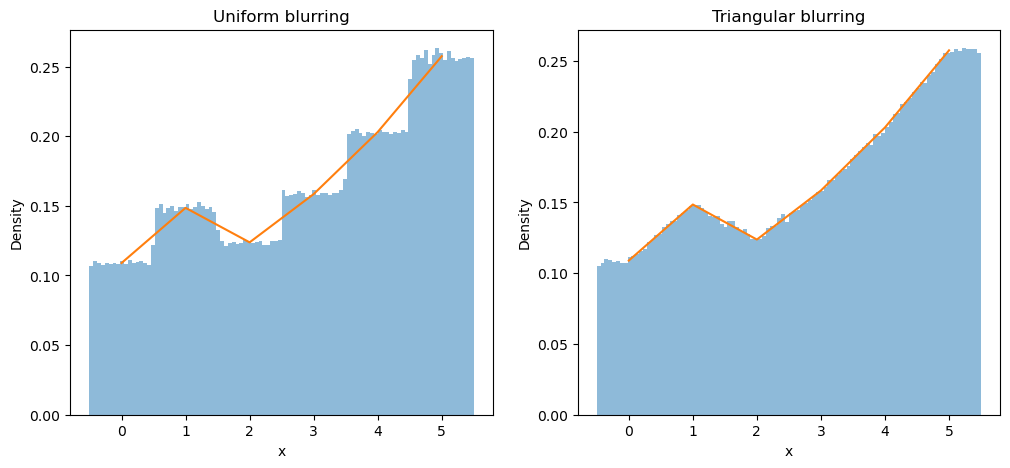

In [99]:
import numpy as np
import matplotlib.pyplot as plt

random_state = np.random.RandomState(498238)

data = np.array([2.2, 3, 2.5, 3.2, 4.1, 5.2])

idx = random_state.choice(np.arange(data.size), p=data/ data.sum(), size=1_000_000)
x_tri = idx + random_state.triangular(-1, 0, 1, size=1_000_000)
x_uni = idx + random_state.uniform(-0.5, 0.5, size=1_000_000)

# constant extrapolation within the edge bins
overflow_left = x_tri < -0.5
x_tri[overflow_left] = - x_tri[overflow_left] - 1

overflow_right = x_tri > data.size - 0.5
x_tri[overflow_right] = 2 * (data.size - 0.5) - x_tri[overflow_right]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(x_uni, bins=100, alpha=0.5, label="Data", density=True);
axes[0].plot(data/ data.sum());
axes[0].set_title("Uniform blurring")
axes[0].set_xlabel("x")
axes[0].set_ylabel("Density")

axes[1].hist(x_tri, bins=100, alpha=0.5, label="Data", density=True);
axes[1].plot(data/ data.sum());
axes[1].set_title("Triangular blurring")
axes[1].set_xlabel("x")
axes[1].set_ylabel("Density")